<a href="https://colab.research.google.com/github/pathakji00/fun-work/blob/main/manual_back.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import math
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
print(torch.__version__)
print(pd.__version__)




2.11.0+cpu
2.2.3


In [ ]:
class value:
  def __init__(self,data,_children=(),_op = '',label = ''):
    self.data = data
    self._prev = set(_children)
    self._op = _op
    self.grad = 0
    self.label = label
    #for auto backprop
    self._backward =  lambda : None



  def __repr__(self):
    return f"value(data={self.data})"
  def __add__(self,other):
    out = value(self.data +other.data,(self,other),'+')
    def _backward():
      self.grad = 1.0*out.grad
      other.grad = 1.0*out.grad
    out._backward = _backward
    return out
  def __mul__(self,other):
    out = value(self.data *other.data,(self,other),'+')
    def _backward():
      self.grad = other.data*out.grad
      other.grad = self.data*out.grad
    out._backward = _backward


    return out

  def tanh(self):
    x = self.data
    t = (math.exp(2*x)-1)/(math.exp(2*x)+1)
    out = value(t,(self,),'tanh')
    def _backward():
      self.grad = (1-t**2)*out.grad
    out._backward = _backward
    return out



a = value(2.0,label = 'a')
b = value(-3.0,label = 'b')
c = value(6.0,label = 'c')
d = a*b +c;d.label = 'd'
e = a*b;e.label = 'e'
f = d+e;f.label = 'f'
f.grad = 1
d.grad = 1
e.grad = 1
c.grad = 1
a.grad = b.data
b.grad = a.data




In [ ]:
from graphviz import Digraph
def trace(root):
  nodes,edges = set(),set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child,v))
        build(child)
  build(root)
  return nodes,edges
def draw_dot(root):
  dot = Digraph(format='svg',graph_attr={'rankdir':'LR'})
  nodes,edges = trace(root)
  for n in nodes:
    uid = str(id(n))
    dot.node(name=uid,label="{%s|data %.4f|grad%.4f}" % (n.label,n.data,n.grad),shape='record')
    if n._op:
      dot.node(name=uid +n._op,label=n._op)
      dot.edge(uid +n._op,uid)
  for n1,n2 in edges:
    dot.edge(str(id(n1)),str(id(n2)) + n2._op)
  return dot

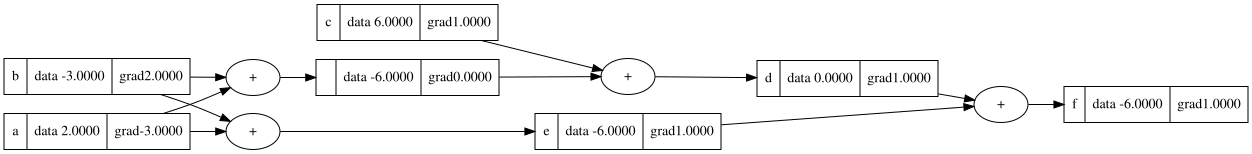

In [ ]:
draw_dot(f)

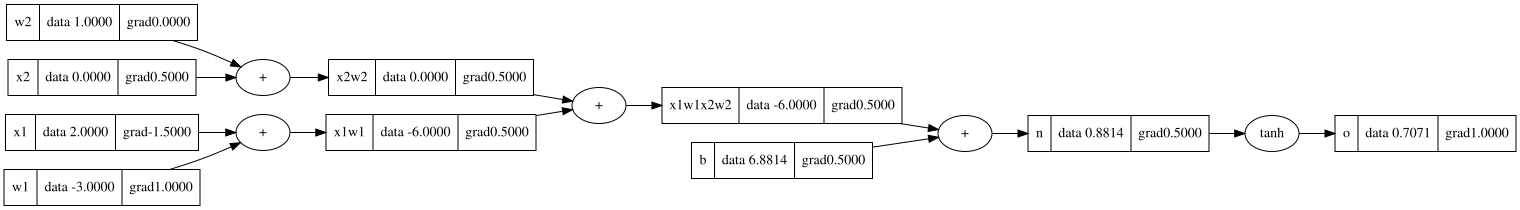

In [ ]:
#inputs x1,x2
x1 = value(2.0,label= 'x1')
x2 = value(0.0,label= 'x2')
#weights of the neuron
w1 = value(-3.0,label= 'w1')
w2 = value(1.0,label= 'w2')
#bias
b = value(6.8813735870195432,label= 'b')
#x1w1+x2w2+b
x1w1 = x1*w1;x1w1.label = 'x1w1'
x2w2 = x2*w2;x2w2.label = 'x2w2'
x1w1x2w2 = x1w1+x2w2;x1w1x2w2.label = 'x1w1x2w2'
n = x1w1x2w2+b;n.label = 'n'
o = n.tanh();o.label = 'o'


#backpropagate manually

o.grad = 1.0
o._backward()
n._backward()
b._backward()
x1w1x2w2._backward()
x1w1._backward()
x2w2._backward()
x1._backward()
x2._backward()
w1._backward()
w2._backward()



draw_dot(o)